# AgriOptima Mandi prices

Predict the next recorded monthly price for a crop and region. Follow the numbered steps from top to bottom. The website offers 95 crops with price records in both Haryana and Punjab. The training pool also includes other commodity and regional histories. Prices are in rupees per quintal.

## 1 Import libraries and locate the project
Pandas reads the tables. Random Forest learns price patterns. Joblib saves the fitted model.

In [1]:
# Market price prediction for every commodity with sufficient recorded history.
from pathlib import Path
import pandas as pd
import numpy as np
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
root = Path.cwd()
if root.name == 'models': root = root.parent

## 2 Read and clean the market reports
The first loop reads one crop file at a time. The second creates monthly regional medians. The four lags use only earlier calendar months. Empty or invalid source files are skipped. Keep missing months empty so a three-month gap is not mistaken for one month.

In [2]:
parts = []
for path in sorted((root / 'DataSets/india_mandi_prices_2000_2024').glob('*.csv')):
    try:
        data = pd.read_csv(
            path,
            usecols=lambda c: c in [
                'State Name', 'Reported Date',
                'Modal Price (Rs./Quintal)', 'Modal Price'
            ],
            low_memory=False
        )
        price_col = 'Modal Price (Rs./Quintal)' if 'Modal Price (Rs./Quintal)' in data else 'Modal Price'
        data['price'] = pd.to_numeric(data[price_col], errors='coerce')
        data['date'] = pd.to_datetime(data['Reported Date'], format='%d %b %Y', errors='coerce')
        data['date'] = data['date'].fillna(pd.to_datetime(data['Reported Date'], format='%Y-%m-%d', errors='coerce'))
        data = data.loc[data.date.notna() & np.isfinite(data.price) & data.price.gt(0)].drop_duplicates()
        data['date'] = data.date.dt.to_period('M').dt.to_timestamp()
        for scope in ['All'] + sorted(data['State Name'].dropna().astype(str).unique().tolist()):
            selected = data if scope == 'All' else data[data['State Name'].str.casefold().eq(scope.casefold())]
            monthly = selected.groupby('date').price.median().sort_index()
            if len(monthly) < 30:
                continue
            frame = monthly.reindex(
                pd.date_range(
                    monthly.index.min(),
                    monthly.index.max() + pd.offsets.MonthBegin(1),
                    freq='MS'
                )
            ).rename_axis('date').reset_index()
            frame.columns = ['date','price']
            frame['crop'] = path.stem
            frame['state'] = scope
            for lag in [1, 2, 3, 12]:
                frame['lag_' + str(lag)] = frame.price.shift(lag)
            frame['month'] = frame.date.dt.month
            frame['year'] = frame.date.dt.year
            parts.append(frame)
    except (ValueError, KeyError, pd.errors.EmptyDataError) as error:
        print(path.name, str(error))

Betelnuts.csv No columns to parse from file


Broomstick(Flower Broom).csv No columns to parse from file


Camel Hair.csv No columns to parse from file


Fig(Anjura-Anjeer).csv No columns to parse from file


Goat Hair.csv No columns to parse from file


Jaggery.csv No columns to parse from file


Ladies Finger.csv No columns to parse from file


Nargasi.csv No columns to parse from file


Saffron.csv No columns to parse from file
Seegu.csv No columns to parse from file


## 3 Choose the inputs and target
The target is the recorded monthly price. The seven inputs are the crop name, prices 1, 2, 3 and 12 months earlier, calendar month and year. Region chooses the local history; it is not an extra model feature.

In [3]:
monthly = pd.concat(parts,ignore_index=True)
features = ['crop','lag_1','lag_2','lag_3','lag_12','month','year']
ready = monthly.dropna(subset=features+['price']).copy()

## 4 Explore the data
Count records and inspect a regional price trend before fitting the model.

    crop state       date   price
0  Ajwan   All 2002-05-01  2200.0
1  Ajwan   All 2002-06-01  1900.0
2  Ajwan   All 2002-07-01  1950.0
3  Ajwan   All 2002-08-01  2100.0
4  Ajwan   All 2002-09-01  2300.0
Missing prices: 165240
Complete model rows: 346912


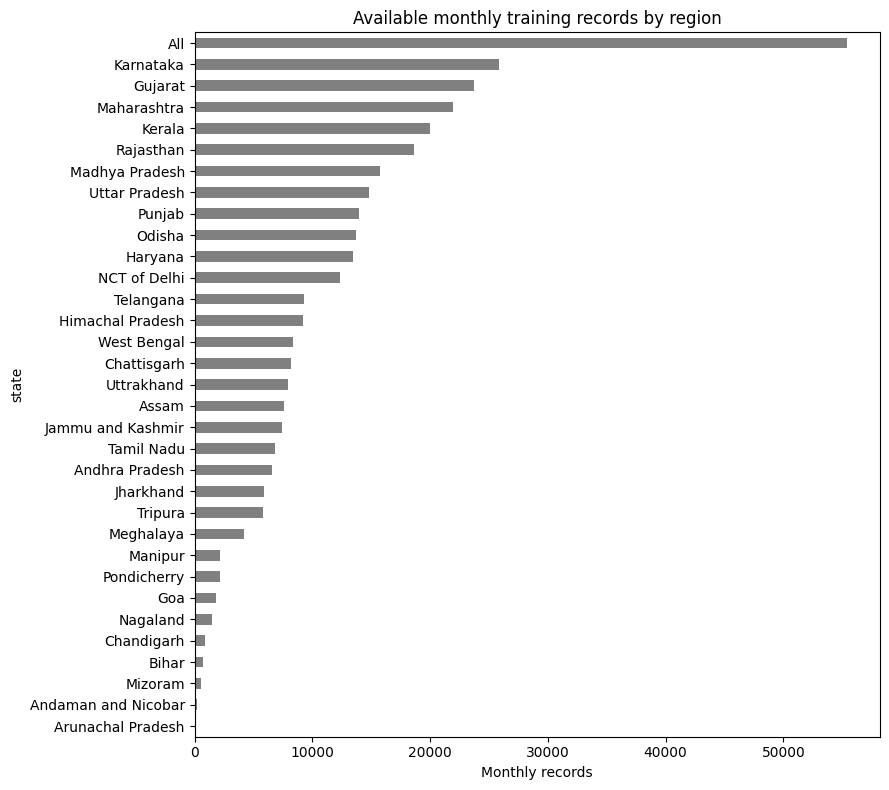

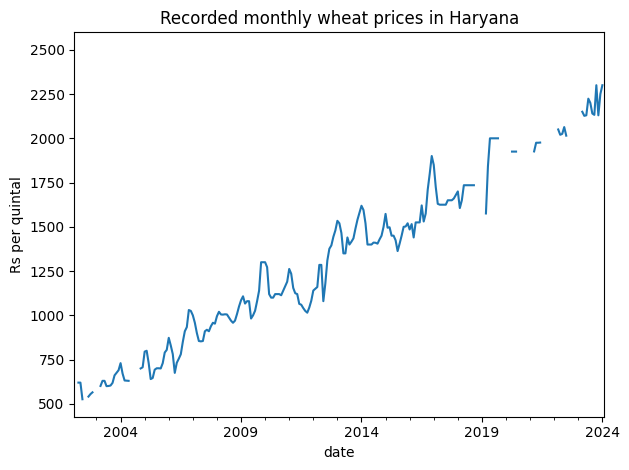

In [4]:
# EDA: coverage and a price example from actual model input history.
import matplotlib.pyplot as plt
print(monthly[['crop','state','date','price']].head())
print('Missing prices:',monthly.price.isna().sum())
print('Complete model rows:',len(ready))
coverage = ready.groupby('state').size().sort_values()
coverage.plot.barh(figsize=(9,8),color='gray',title='Available monthly training records by region')
plt.xlabel('Monthly records');plt.tight_layout();plt.show()
example = monthly[(monthly.crop=='Wheat') & (monthly.state=='Haryana')]
if not example.empty:
    example.plot(x='date',y='price',legend=False,title='Recorded monthly wheat prices in Haryana')
    plt.ylabel('Rs per quintal');plt.tight_layout();plt.show()

## 5 Split earlier and later months
Earlier dates train the model. Later dates test it. The same calendar cutoff applies across crops and regions.

In [5]:
# Calendar-based split: no future observations enter the training set.
cutoff = ready.date.quantile(.8)
train = ready[ready.date < cutoff]
test = ready[ready.date >= cutoff]

## 6 Create the model
One-hot encoding changes crop names into indicator columns. The forest averages 60 decision trees. Depth 14 and at least 5 rows per leaf limit tree complexity.

In [6]:
preprocess = ColumnTransformer([
    ('categories', OneHotEncoder(handle_unknown='ignore'), ['crop']),
    ('numbers', 'passthrough', features[1:])
])
model = make_pipeline(
    preprocess,
    RandomForestRegressor(
        n_estimators=60,
        max_depth=14,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=2
    )
)

## 7 Train and compare with a simple baseline
Fit only on earlier records. Predict the later records. Compare the forest with repeating the previous month’s price. Lower mean absolute error is better.

In [7]:
model.fit(train[features],train.price)
prediction = model.predict(test[features])
metrics = {
    'test_rows': len(test),
    'training_rows': len(train),
    'forest_mae': mean_absolute_error(test.price, prediction),
    'previous_month_mae': mean_absolute_error(test.price, test.lag_1),
    'cutoff': str(cutoff)
}
# Error by commodity prevents a single aggregate from hiding weak forecasts.

## 8 Examine individual prediction errors
Save the error for each test record. Grouping by crop and region helps reveal differences that an overall average can hide.

In [8]:
scored = test[['crop','state','date','price','lag_1']].copy()
scored['prediction'] = prediction
scored['absolute_error'] = abs(scored.price - scored.prediction)
scored['baseline_error'] = abs(scored.price - scored.lag_1)

## 9 Fit the website model on available history
After recording the test comparison, fit the same settings on all model-ready historical rows. This model supports forecasts after the recorded history.

In [9]:
# Refit the same configuration on available history for the next recorded month.
model.fit(ready[features],ready.price)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('categories',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['crop']),
                                                 ('numbers', 'passthrough',
                                                  ['lag_1', 'lag_2', 'lag_3',
                                                   'lag_12', 'month',
                                                   'year'])])),
                ('randomforestregressor',
                 RandomForestRegressor(max_depth=14, min_samples_leaf=5,
                                       n_estimators=60, n_jobs=2,
                                       random_state=42))])

## 10 Save the model and result tables
The website reads the same model bundle and monthly history saved here. The comparison table describes the earlier chronological test, not the final model fitted on all history.

In [10]:
output = root / 'results/mandi_prices'
output.mkdir(parents=True,exist_ok=True)
monthly.to_csv(output/'monthly_crop_prices.csv',index=False)
scored.to_csv(output/'held_out_predictions.csv',index=False)
scored.groupby(['crop','state'])[['absolute_error','baseline_error']].mean().to_csv(output/'errors_by_crop_region.csv')
print('Monthly history rows:',len(monthly), 'regions:',monthly.state.nunique())
print('Chronological split overlap:',len(set(train.date) & set(test.date)))
pd.DataFrame([metrics]).to_csv(output/'model_comparison.csv',index=False)
joblib.dump({'model':model,'features':features,'metrics':metrics},root/'backend/saved_models/market_prices.joblib',compress=3)
print(metrics)
print('Commodities with model-ready history:',ready.crop.nunique())

Monthly history rows: 614498 regions: 33


Chronological split overlap: 0
{'test_rows': 69641, 'training_rows': 277271, 'forest_mae': 822.1338518451724, 'previous_month_mae': 683.4942973966486, 'cutoff': '2019-12-01 00:00:00'}
Commodities with model-ready history: 295


## 11 Predict the next month for each crop and region
If a required past month is missing, use the median of the region’s last 12 observed prices. This is an explicit data-based assumption at prediction time. It needs separate evaluation on sparse histories. No future prices or fixed rupee amounts are used.

In [11]:
# Website forecasts use only history before each region's next recorded month.
# If a particular lag is missing, use the median of the last 12 observed regional prices.
# This is an explicit data-derived inference assumption, not a current price quote.
forecasts = []
for (crop, state), history in monthly.groupby(['crop','state']):
    history = history.sort_values('date')
    row = history.tail(1).copy()
    past = history.loc[history.date.lt(row.date.iloc[0]), 'price'].dropna().tail(12)
    if past.empty: continue
    for feature in features:
        if feature.startswith('lag_') and row[feature].isna().any():
            row.loc[:,feature] = float(past.median())
    value = float(model.predict(row[features])[0])
    forecasts.append({'crop':crop,'state':state,'forecast_month':str(row.date.iloc[0]),'predicted_price':value})
pd.DataFrame(forecasts).to_csv(output/'next_month_forecasts.csv',index=False)

## 12 Read the results
The recorded chronological test uses 277,271 training rows and 69,641 test rows. Random Forest MAE is about Rs 822.13 per quintal, while repeating the previous month gives about Rs 683.49. The baseline is better on this combined test. Errors across crops have different price scales, so inspect the crop-region error table too. These are historical estimates rather than live mandi quotes.